# 01 · Baselines and the linear reference (E0, E1)

**Question:** what is the floor every model has to beat, scored the same honest way?

Protocol (fixed in the P3 plan):
- 3 expanding-window folds, validated on 12-month windows: Aug 2022 → Aug 2025.
- Validation rows come from the **proxy** table, so archived forecast weather, just like serving. Uri hours are not scored.
- Headline metric: **MAPE**. Champion rule: lowest MAPE **and** Peak-MAPE no worse than the best baseline's. Peak-MAPE is over the top 5% of actual load in each fold.

All logic lives in `src/shef/models/`. This notebook only runs and records it. Every run is logged to MLflow (`shef2-day-ahead`).

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from shef import store
from shef.models import baselines, cv, data, gbdt, plots, report, tracking

pd.set_option("display.width", 160)
mlflow = tracking.init()
tables = data.load_tables(data.default_features())
{k: v.shape for k, v in tables.items()}

{'obs': (94175, 45), 'proxy': (48576, 45)}

## E0 · Baselines

| Baseline | Rule |
|---|---|
| `same_hour_last_week` | load at the same hour 7 days earlier (`load_lag_168`) |
| `same_hour_latest` | the freshest legal copy of the same hour: yesterday for target hours 00–08, two days ago for 09–23 |
| `blend_latest_lastweek` | the average of the two |

v1's "persistence" (yesterday's load at the same hour) is not available at 10:00 for target hours 09–23, so it isn't a legal baseline here.

In [2]:
base = baselines.score_on_folds(tables)
names = list(baselines.BASELINES)
report.summary(base, names)

,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape
same_hour_last_week,11.37,9.54,1397.30,-0.07,11.11,10.68,12.31
same_hour_latest,8.18,6.50,1013.90,-0.02,8.49,7.81,8.24
blend_latest_lastweek,8.28,7.46,1008.92,-0.05,8.25,7.88,8.73


**Independent check.** The lag-168 MAPE recomputed straight from the clean load table, not through the feature builder. The two must agree.

In [3]:
L = store.read("clean", "load").set_index("ts_utc")["load_mw"]
y = L.reindex(base["ts_utc"]).to_numpy()
lag = L.reindex(base["ts_utc"] - pd.Timedelta(hours=168)).to_numpy()
ok = ~np.isnan(y) & ~np.isnan(lag)
independent = np.mean(np.abs(lag[ok] - y[ok]) / y[ok]) * 100
print(f"independent lag-168 MAPE {independent:.2f}%  vs builder {report.summary(base, ['same_hour_last_week']).loc['same_hour_last_week','mape']:.2f}%")

independent lag-168 MAPE 11.37%  vs builder 11.37%


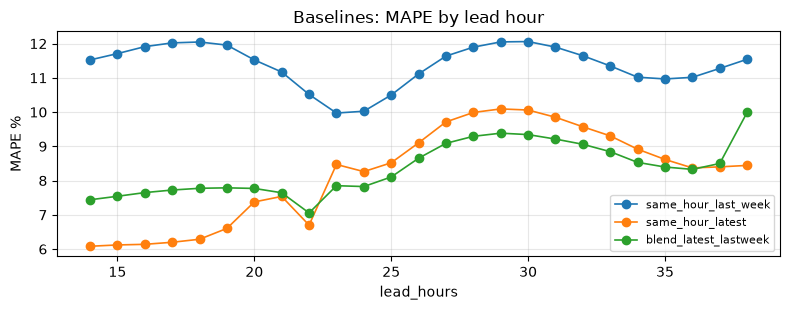

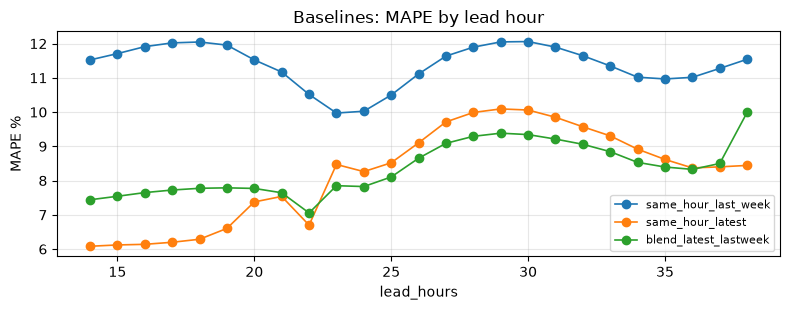

In [4]:
plots.compare_by(base, "lead_hours", names, "Baselines: MAPE by lead hour")

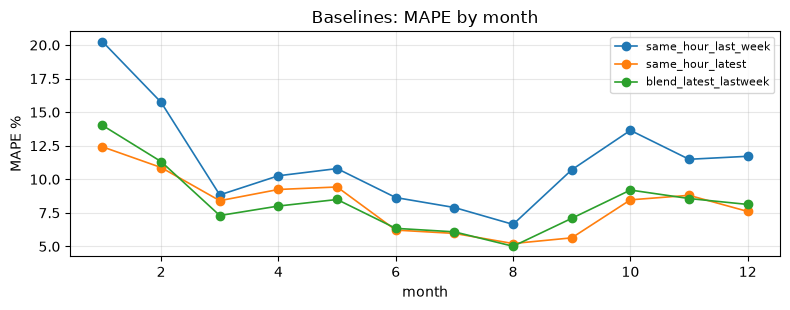

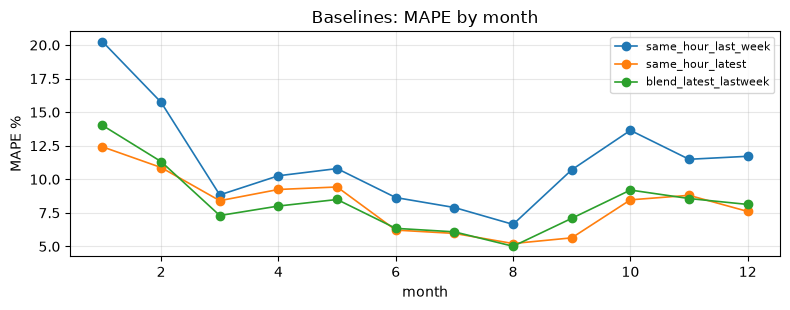

In [5]:
plots.compare_by(base, "month", names, "Baselines: MAPE by month")

In [6]:
for n in names:
    report.log_scored(f"E0_{n}", base, n, {"model": n, "experiment": "E0", "train_source": "none"}, tags={"experiment": "E0"})
print("logged", len(names), "baseline runs")

🏃 View run E0_same_hour_last_week at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/2f31fb48156b482aa20d26943e816798
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


🏃 View run E0_same_hour_latest at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/ad5d29e7e22a465f913af3f0267f3390
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


🏃 View run E0_blend_latest_lastweek at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/aa4a2c47dbc041f38bd75519cc7a911a
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


logged 3 baseline runs


## E1 · Ridge regression

A linear model on the default feature set: every day-ahead feature in `features.yaml` except forecast humidity and precipitation, which are opt-in in E5. Inputs are median-imputed and scaled. Trained on `obs` (ERA5 as a perfect forecast, 2016+) and validated on `proxy`.

  E1_ridge                     fold 1: MAPE 7.04%  peak 7.96%  (train 57,190 / val 8,760)


  E1_ridge                     fold 2: MAPE 6.17%  peak 9.71%  (train 65,950 / val 8,784)


  E1_ridge                     fold 3: MAPE 5.69%  peak 7.60%  (train 74,734 / val 8,760)


🏃 View run E1_ridge at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/846baf0a3b4b49d2b295b61f867af291
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


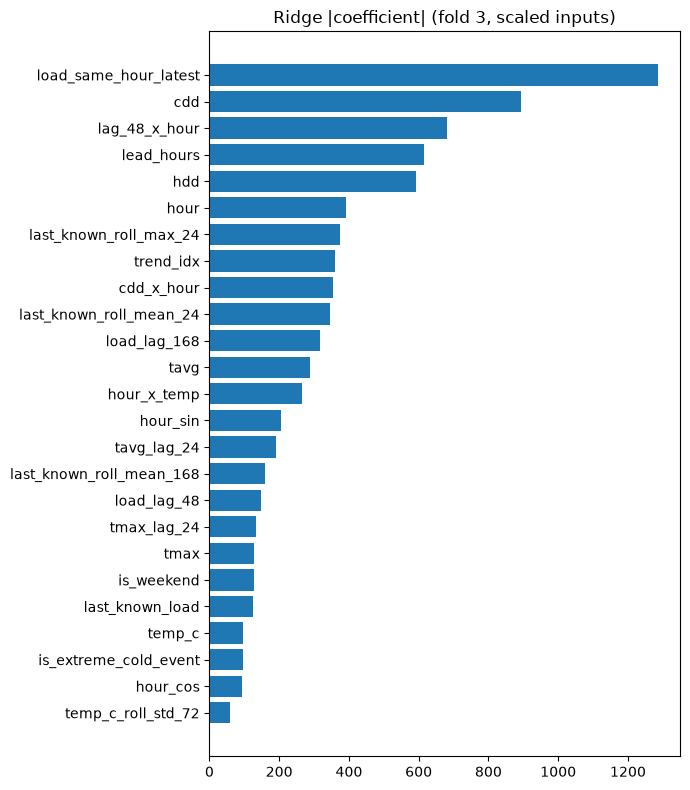

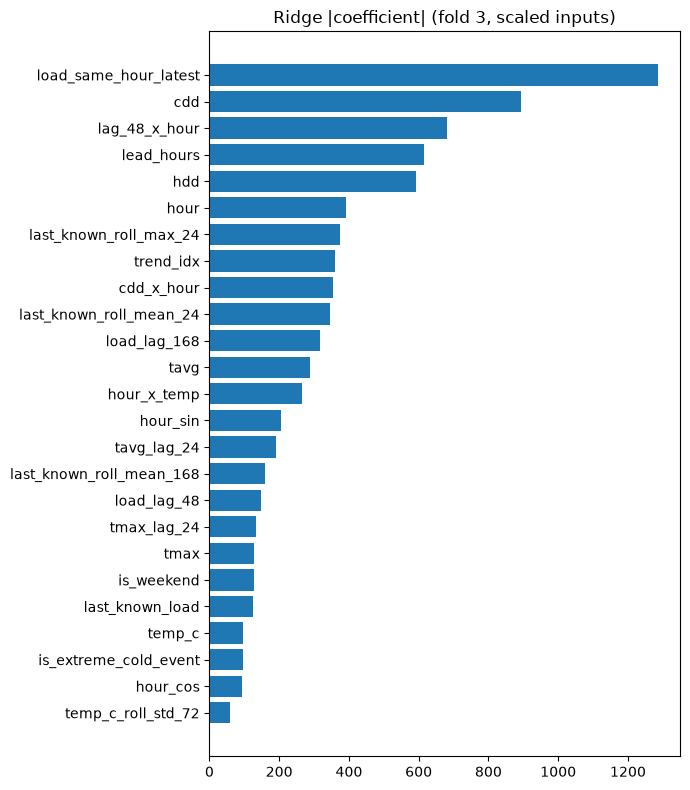

In [7]:
ridge = cv.run_cv(cv.Spec("E1_ridge", lambda: gbdt.ridge(), target="raw"), tables)
coefs = ridge.models[3][0].steps[-1][1].coef_
fig_coef = plots.importance(ridge.spec.features, np.abs(coefs), title="Ridge |coefficient| (fold 3, scaled inputs)")
report.log_result(ridge, figures={"coefficients": fig_coef}, tags={"experiment": "E1"})
fig_coef

## Floor

In [8]:
both = base.merge(ridge.scored[["ts_utc", "pred"]].rename(columns={"pred": "ridge"}), on="ts_utc")
floor = report.summary(both, names + ["ridge"])
best_peak = floor.loc[names, "peak_mape"].min()
floor["passes_peak_rule"] = floor["peak_mape"] <= best_peak
floor

,mape,peak_mape,rmse,bias_pct,fold1_mape,fold2_mape,fold3_mape,passes_peak_rule
same_hour_last_week,11.37,9.54,1397.30,-0.07,11.11,10.68,12.31,False
same_hour_latest,8.18,6.50,1013.90,-0.02,8.49,7.81,8.24,True
blend_latest_lastweek,8.28,7.46,1008.92,-0.05,8.25,7.88,8.73,False
ridge,6.30,8.43,762.14,-3.36,7.04,6.17,5.69,False


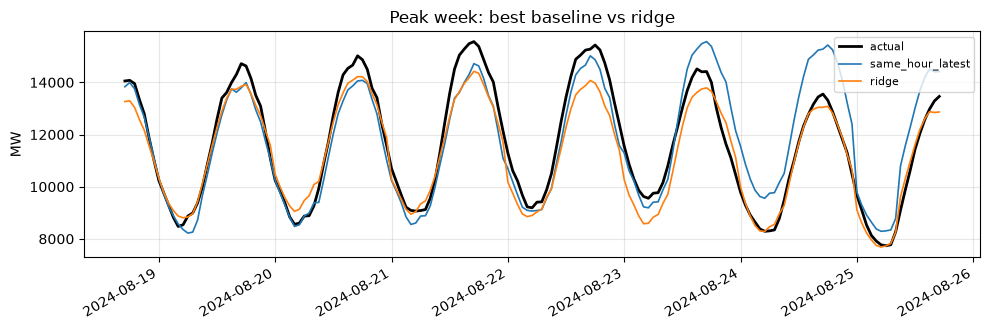

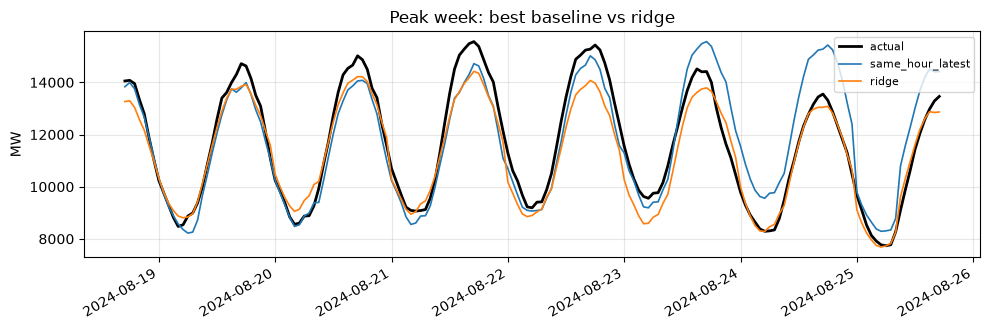

In [9]:
plots.peak_week(both, ["same_hour_latest", "ridge"], "Peak week: best baseline vs ridge")

## Reading

- **The floor is `same_hour_latest`: 8.18% MAPE, 6.50% Peak-MAPE.** Every later model has to beat both.
  - `same_hour_last_week` is clearly worse at 11.37%, because a week-old value misses weather changes.
  - Averaging the two doesn't help (8.28%).
- **Freshness is worth about 2.6 points of MAPE.**
  - `same_hour_latest` scores 6.56% on target hours 00–08, which get yesterday's value, and 9.15% on hours 09–23, which only have a two-day-old value.
  - `same_hour_last_week` is flat across lead hours, at about 11.2–11.6%.
  - That's the cost of the 10:00 forecast time.
- **Ridge reaches 6.30% MAPE but 8.43% Peak-MAPE**, worse at the peaks than the best baseline, and it's biased 3.4% low. A linear model can't bend with the temperature–load curve on hot afternoons. Under the champion rule it doesn't qualify.
- **Next:** `02_gbdt.ipynb`, tree models × target forms.